# Cancer: AUTOENCODIX-Annealing mit den stärksten AUC-Korrelationen

Steuerungssignal: **MRRE false, Trustworthiness oder LCMC**, jeweils einzeln.
Die bisherige explorative Auswertung der 240 TCGA-Läufe motiviert diese Auswahl;
sie ist kein unabhängiger Wirksamkeitsnachweis für einen Annealer.

Wir verwenden den nativen AUTOENCODIX-Trainer und `VarixLoss`:
`Loss = Rekonstruktion + β_config × w × KL`. Unser Scheduler erhöht `w` stufenweise,
wenn die gewählte Metrik auf dem festen Validierungs-Subset über dem Zielband liegt,
und senkt ihn unterhalb des Zielbands. Im Band wird β gehalten und bei Abweichungen
wieder angepasst. Das ist eine beobachtete
Preservation-Grenze, keine harte mathematische Constraint der Modellgewichte.

**Rate ist nur Collapse-Diagnostik. AUC und Labels werden nie zur β-Steuerung verwendet.**
Standard: ein vorbereiteter TCGA-Lauf mit 500 Epochen; kein automatischer Start.
Ein Modell wird auf allen 33 Krebsarten trainiert und getrennt auf allen 33 sowie
den acht Präsentations-Krebsarten bewertet. Das sind keine zwei Trainingskohorten.
Die breite Large-Scale-Serie bleibt während dieses fokussierten Versuchs pausiert.

In [1]:
from pathlib import Path
from dataclasses import replace
import hashlib
import json
import os
import subprocess
import sys
import re
import time
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "beta_vae_experiments":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "beta_vae_experiments" / "preservation_annealing.py").is_file():
    raise RuntimeError("Notebook aus dem Repo oder beta_vae_experiments öffnen.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from beta_vae_experiments.preservation_annealing import PreservationAnnealingConfig, measure_preservation
from beta_vae_experiments.metrics.information_theoretic import compute_conditional_kl_matrix
from beta_vae_experiments.metrics.latent_usage import PosteriorCollapseConfig

OUTPUT_ROOT = PROJECT_ROOT / "beta_vae_experiments" / "outputs" / "cancer_annealing_focus"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

## 1. Auswahl und Einstellungen

Die Tabelle unten zeigt die tatsächlich gespeicherten Pearson-/Spearman-Werte.
Wir wählen drei stark korrelierte lokale Preservation-Maße; sie sind untereinander
redundant und werden deshalb zunächst **einzeln** als Steuerungssignal getestet.

`METRICS = ("trustworthiness",)` bedeutet ein Modell. Für einen Vergleich alternativ
`("mrre_false", "trustworthiness", "lcmc")` wählen: dann entstehen drei Modelle.

`TARGET_MODE="absolute"`, `TARGET_VALUE=0.90`: Trustworthiness soll ungefähr
0,9 erreichen. Das ist ein absoluter Score, nicht 90 % des Warm-up-Werts.
Mit `ANNEALING_RULE="target"` wird β bei TW > 0,91 erhöht, bei TW < 0,89
gesenkt und im Zielband gehalten. Verlässt die Metrik das Band später wieder, wird
erneut angepasst. Bei Richtungswechseln werden die β-Schritte kleiner. Das Modell
trainiert bis Epoche 500; Rate und AUC steuern weiterhin nichts.

Messung alle 5 Epochen und Wachstumsfaktor 1,25 ergeben gröbere, schnellere Stufen. Snapshots
bleiben aus Speichergründen alle 20 Epochen. Modelllernen und Messintervalle können
Überschwingen verursachen; eine exakt eingehaltene harte 0,9-Grenze wird nicht zugesichert.
Wird zuerst der β-Deckel erreicht, zeigt das Notebook dies als eigenen Stoppgrund.

Für spätere relative Versuche: `TARGET_MODE="relative_warmup"` setzen; dann ist der
Wert ein Anteil des Warm-up-Scores. MRRE false und LCMC sind ebenfalls höher-besser;
LCMC kann negativ werden und benötigt für relative Ziele eine positive Referenz.

`PRESET="tcga_pilot"`: 500 Epochen, d=8, Seed 17, GPU.
`PRESET="cpu_demo"`: 30 Epochen mit Circle in 8 Latentdimensionen, nur Anbindungstest.
Mit `RUN_TRAINING=False` werden nur vorhandene Resultate geladen.

In [2]:
CANDIDATES = {"mrre_false": "geometry_mu_mrre_false_zadu_k20",
              "trustworthiness": "geometry_mu_trustworthiness_zadu_k20",
              "lcmc": "geometry_mu_lcmc_zadu_k20"}
summary_path = PROJECT_ROOT / "beta_vae_experiments/analysis_results/metric_selection/auc_correlations_summary.csv"
summary = pd.read_csv(summary_path)
selection = summary[summary.task.eq("cancer") & summary["mode"].eq("values")
                    & summary.metric.isin(CANDIDATES.values())]
display(selection[["metric", "pearson", "spearman", "gain_spearman", "n_trajectories"]]
        .sort_values("pearson", ascending=False))

PRESET = "tcga_pilot"
METRICS = ("trustworthiness",)
TARGET_MODE = "absolute"
ANNEALING_RULE = "target"
TARGET_TOLERANCE = 0.01
TARGET_VALUE = 0.90
TARGET_SCORES = {metric: TARGET_VALUE for metric in CANDIDATES}
RUN_TRAINING = True
RERUN_COMPLETED = False
SEED, SPLIT_SEED = 17, 2
PRESETS = {
    "tcga_pilot": dict(epochs=500, latent_dim=8, device="cuda", beta_over_d=0.015,
                       warmup_epochs=100, step_epochs=5, n_subsample=800, k=20,
                       every=20, w_min=0.0001, growth=1.25),
    "cpu_demo": dict(epochs=30, latent_dim=8, device="cpu", beta_over_d=1.0,
                     warmup_epochs=10, step_epochs=5, n_subsample=120, k=10,
                     every=5, w_min=0.001, growth=2.0),
}
parameters = PRESETS[PRESET].copy()
assert METRICS and set(METRICS) <= CANDIDATES.keys()
display(pd.Series(parameters, name=PRESET).to_frame())

,metric,pearson,spearman,gain_spearman,n_trajectories
23,geometry_mu_mrre_false_zadu_k20,0.990318,0.97619,0.0,24
39,geometry_mu_trustworthiness_zadu_k20,0.988134,0.97619,0.0,24
21,geometry_mu_lcmc_zadu_k20,0.984278,0.97619,0.0,24


,tcga_pilot
epochs,500
latent_dim,8
device,cuda
beta_over_d,0.015
warmup_epochs,100
step_epochs,5
n_subsample,800
k,20
every,20
w_min,0.0001


## 2. Eine native Trainingskonfiguration je gewählter Metrik

Gleiche Daten, gleicher Split, gleicher Seed. Der Quellstand des Annealers und die
Konfiguration gehen in den Ergebnisordner-Namen ein, damit alte Ergebnisse nicht
versehentlich als neue Experimente geladen werden.
Nur Posteriors, native Loss-Logs und Snapshots werden beim Pilot erzeugt.
Die gezielte Auswertung unten berechnet ausschließlich die drei gewählten
Preservation-Maße, Rate/ε-δ und Cancer-AUC. Die breite Metrik-Pipeline läuft hier nicht.

In [3]:
def make_notebook_config(metric):
    settings = json.loads((PROJECT_ROOT / "beta_vae_experiments/user_interface/quickstart.json").read_text())
    if PRESET == "cpu_demo":
        settings["dataset"] = dict(id="circle", split_seed=SPLIT_SEED,
                                   options=dict(n_samples=600, dataset_seed=42, radius=1.0))
    else:
        from beta_vae_experiments.user_interface.config import load_config
        source = load_config(str(PROJECT_ROOT / "beta_vae_experiments/user_interface/experiments.json") + "#training.tcga")
        settings["dataset"] = source["dataset"]
        settings["dataset"]["split_seed"] = SPLIT_SEED
        options = settings["dataset"]["options"]
        options["data_root"] = str((PROJECT_ROOT / options["data_root"]).resolve())
        settings["training"]["downstream_targets"] = ["CANCER_TYPE_ACRONYM"]
    controller = dict(mode="preservation", metric=metric, target=TARGET_SCORES[metric],
                      target_mode=TARGET_MODE, rule=ANNEALING_RULE, tolerance=TARGET_TOLERANCE,
                      max_invalid_measurements=3,
                      warmup_epochs=parameters["warmup_epochs"], step_epochs=parameters["step_epochs"],
                      n_subsample=parameters["n_subsample"], k=parameters["k"], seed=31,
                      w_min=parameters["w_min"], growth=parameters["growth"])
    PreservationAnnealingConfig(**controller)
    training = settings["training"]
    training.pop("betas", None)
    training.update(beta_over_d=[parameters["beta_over_d"]], latent_dims=[parameters["latent_dim"]],
                    epochs=parameters["epochs"], device=parameters["device"], seeds=[SEED],
                    anneal_function="3phase-linear", beta_controller=controller,
                    snapshots=dict(enabled=True, every=parameters["every"], downstream=False))
    settings["metrics"]["absolute_core"]["enabled"] = False
    settings["plots"] = dict(enabled=False, per_run=False)
    settings["execution"] = dict(resume_existing=True, rerun_passed=RERUN_COMPLETED)
    settings.pop("output_dir", None)
    settings.pop("experiment_name", None)
    settings["controller_source_sha256"] = hashlib.sha256((PROJECT_ROOT / "beta_vae_experiments/preservation_annealing.py").read_bytes()).hexdigest()
    fingerprint = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:10]
    name = f"{PRESET}_{metric}_{fingerprint}"
    settings.update(experiment_name=name, output_dir=str(OUTPUT_ROOT / name))
    return settings

configs = {metric: make_notebook_config(metric) for metric in METRICS}
config_paths = {}
config_folder = OUTPUT_ROOT / "configs"
config_folder.mkdir(exist_ok=True)
for metric, settings in configs.items():
    path = config_folder / f"{settings['experiment_name']}.json"
    path.write_text(json.dumps(settings, indent=2) + "\n")
    config_paths[metric] = path

environment = {**os.environ, "PYTHONHASHSEED": "2", "MPLCONFIGDIR": "/tmp/mpl-preservation-notebook",
               "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "CUBLAS_WORKSPACE_CONFIG": ":4096:8"}
for path in config_paths.values():
    subprocess.run([sys.executable, "-m", "beta_vae_experiments.new_beta_varix_experiments",
                    str(path), "--preflight"], cwd=PROJECT_ROOT, env=environment, check=True)
display(pd.DataFrame([dict(variant=m, output=s["output_dir"], epochs=parameters["epochs"])
                      for m, s in configs.items()]))

Preflight passed: tcga_pilot_trustworthiness_a7bee9448a (tcga, 1 runs)


,variant,output,epochs
0,trustworthiness,/home/nickok/Projects/MasterThesis/vae-beta-co...,500


### Training mit Live-Fortschritt
**Run All** startet den konfigurierten Lauf oder beobachtet den bereits laufenden Prozess. Der Balken zeigt abgeschlossene Epochen, effektives β und die letzte gemessene Trustworthiness (Ziel: 0,90). Während der Warm-up-Phase ist noch kein Messwert verfügbar. Das vollständige Trainingslog bleibt gespeichert.


In [4]:
def show_progress(bar, run_folder, log_path):
    """Show completed validation epochs and the latest measured controller signal."""
    if log_path.exists():
        epochs = re.findall(r"Epoch (\d+) - Valid Loss:", log_path.read_text(errors="replace"))
        if epochs:
            bar.update(max(0, min(int(epochs[-1]), bar.total) - bar.n))
    logs = sorted((run_folder / "run_analysis").glob("*/controller_log.csv"))
    if logs:
        try:
            history = pd.read_csv(logs[-1])
            if not history.empty:
                latest = history.iloc[-1]
                measured = history.dropna(subset=["metric_value"])
                signal = f"{measured.iloc[-1].metric_value:.3f}" if len(measured) else "warmup"
                bar.set_postfix(beta=f"{latest.effective_beta:.3g}", TW=signal,
                                target=TARGET_VALUE, state=latest.state)
        except (pd.errors.EmptyDataError, pd.errors.ParserError):
            pass  # The training process may currently be writing the CSV.


for metric, path in config_paths.items():
    run_folder = Path(configs[metric]["output_dir"])
    manifest = run_folder / "launcher.json"
    launcher = json.loads(manifest.read_text()) if manifest.exists() else {}
    active = launcher.get("status") in {"running", "analysing"}
    if active:
        try:
            os.kill(int(launcher["pid"]), 0)  # Check liveness without sending a signal.
        except ProcessLookupError:
            raise RuntimeError(f"Veralteter Laufstatus: {manifest}; bitte vor Neustart prüfen.")
        log_path = Path(launcher["log"])
        print("Bestehenden Lauf beobachten; kein zweites Training. Interrupt beendet nur die Anzeige.")
        with tqdm(total=parameters["epochs"], desc=f"TCGA · {metric}", unit="epoch") as bar:
            while True:
                show_progress(bar, run_folder, log_path)
                launcher = json.loads(manifest.read_text())
                if launcher["status"] not in {"running", "analysing"}:
                    if launcher["status"] != "complete":
                        raise RuntimeError(f"Laufstatus: {launcher['status']}; siehe {log_path}")
                    break
                bar.set_description(f"TCGA · {metric}" if launcher["status"] == "running"
                                    else "Training fertig · Auswertung läuft")
                time.sleep(2)
    elif RUN_TRAINING:
        log_path = OUTPUT_ROOT / f"{configs[metric]['experiment_name']}.log"
        with log_path.open("w") as log, tqdm(
            total=parameters["epochs"], desc=f"TCGA · {metric}", unit="epoch"
        ) as bar:
            process = subprocess.Popen(
                [sys.executable, "-u", "-m", "beta_vae_experiments.new_beta_varix_experiments", str(path)],
                cwd=PROJECT_ROOT, env=environment, stdout=subprocess.PIPE,
                stderr=subprocess.STDOUT, text=True,
            )
            try:
                for line in process.stdout:
                    log.write(line)
                    log.flush()
                    if " - Valid Loss:" in line:
                        show_progress(bar, run_folder, log_path)
                if process.wait():
                    raise RuntimeError(f"Training fehlgeschlagen; siehe {log_path}")
                show_progress(bar, run_folder, log_path)
            except BaseException:
                if process.poll() is None:
                    process.terminate()
                process.wait()
                raise
    else:
        print("Kein Training gestartet; vorhandene Ergebnisse werden geladen.")


TCGA · trustworthiness:   0%|          | 0/500 [00:00<?, ?epoch/s]

## 4. β und Steuerungssignal auf Validation

β steigt nur über die gewählte Preservation-Metrik. Rate oder AUC werden hier nicht
verwendet. Ein ungültiger Wert ist kein Nullwert: β wird zurückgenommen; nach drei
aufeinanderfolgenden ungültigen Messungen schlägt der Lauf explizit fehl.
Wir prüfen die Übereinstimmung mit den tatsächlich verwendeten nativen Loss-Faktoren.

trustworthiness {'not_measured': 419, 'ok': 81}
Zielkorridor mindestens einmal erreicht: True
Letzter Zustand/Grund: {'state': 'hold', 'reason': 'target_band'}


,epoch,w,effective_beta,metric_value,target,state,status,warning
99,100,0.000000,0.000000,0.959779,0.9,warmup,ok,NaN
104,105,0.000100,0.000012,0.966905,0.9,seeking,ok,NaN
109,110,0.000125,0.000015,0.966815,0.9,seeking,ok,NaN
114,115,0.000156,0.000019,0.966935,0.9,seeking,ok,NaN
119,120,0.000195,0.000023,0.968165,0.9,seeking,ok,NaN
...,...,...,...,...,...,...,...,...
479,480,0.080779,0.009694,0.895956,0.9,hold,ok,NaN
484,485,0.080779,0.009694,0.895593,0.9,hold,ok,NaN
489,490,0.080779,0.009694,0.896112,0.9,hold,ok,NaN
494,495,0.080779,0.009694,0.897403,0.9,hold,ok,NaN


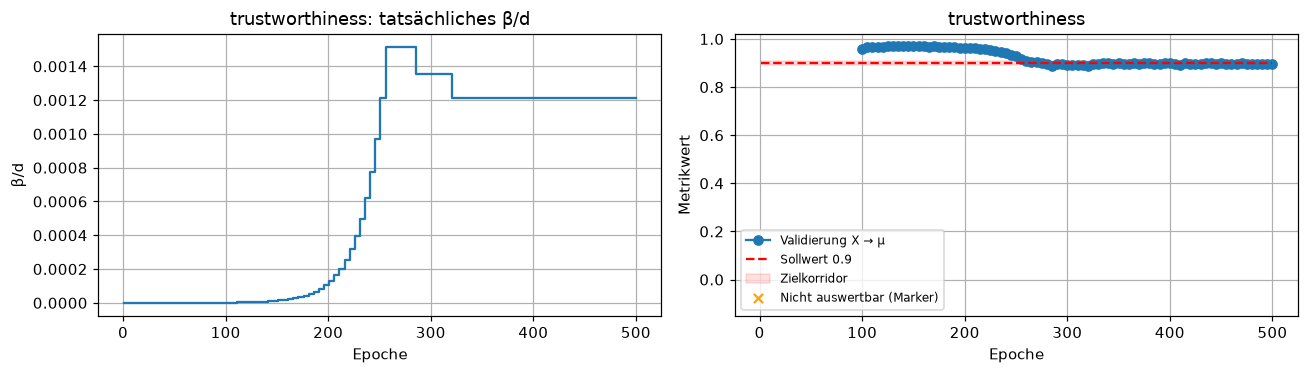

In [5]:
runs, controller_tables, loss_tables = {}, {}, {}
for metric, settings in configs.items():
    output = Path(settings["output_dir"])
    overview_path = output / "experiment_metrics.csv"
    if not overview_path.exists():
        print(f"{metric}: noch kein Lauf; RUN_TRAINING aktivieren, wenn die Einstellungen passen.")
        continue
    overview = pd.read_csv(overview_path)
    if len(overview) != 1 or not overview.status.eq("ok").all():
        raise RuntimeError(overview.to_string())
    folder = output / "run_analysis" / overview.iloc[0].run_name
    runs[metric] = folder
    controller = pd.read_csv(folder / "controller_log.csv")
    losses = pd.read_csv(folder / "epoch_losses.csv")
    if len(controller) != parameters["epochs"]:
        raise ValueError("Controller-Log enthält nicht alle Epochen.")
    for split in ("train", "valid"):
        compared = controller.merge(losses[losses.split.eq(split)], on="epoch")
        if len(compared) != len(controller):
            raise ValueError("Loss- und Controller-Epochen stimmen nicht überein.")
        np.testing.assert_allclose(compared.effective_beta, compared.effective_beta_factor, rtol=1e-7, atol=1e-12)
    controller_tables[metric] = controller
    loss_tables[metric] = losses
    print(metric, controller.status.value_counts().to_dict())
    reached = (controller.metric_value.notna() & ((controller.metric_value-controller.target).abs() <= controller.tolerance + 1e-12)).any()
    print("Zielkorridor mindestens einmal erreicht:", bool(reached))
    if "reason" in controller:
        print("Letzter Zustand/Grund:", controller.iloc[-1][["state", "reason"]].to_dict())
    if not controller.status.eq("ok").any():
        print("ACHTUNG: Kein gültiges Steuerungssignal; dies ist kein erfolgreicher Annealing-Nachweis.")
    display(controller.loc[~controller.status.eq("not_measured"),
        ["epoch", "w", "effective_beta", "metric_value", "target", "state", "status", "warning"]])

if runs:
    fig, axes = plt.subplots(len(METRICS), 2, figsize=(12, 3.5 * len(METRICS)), squeeze=False)
    for row, metric in enumerate(METRICS):
        table = controller_tables[metric]
        axes[row, 0].step(table.epoch, table.beta_over_d, where="post")
        axes[row, 0].set(title=f"{metric}: tatsächliches β/d", xlabel="Epoche", ylabel="β/d")
        measured = table[table.status.eq("ok")]
        axes[row, 1].plot(measured.epoch, measured.metric_value, "o-", label="Validierung X → μ")
        axes[row, 1].plot(table.epoch, table.target, color="red", linestyle="--", label=f"Sollwert {TARGET_VALUE:g}")
        axes[row, 1].fill_between(table.epoch, table.target-table.tolerance, table.target+table.tolerance, color="red", alpha=.12, label="Zielkorridor")
        missing = table[table.status.eq("unavailable")]
        axes[row, 1].scatter(missing.epoch, np.full(len(missing), 0.03), marker="x", color="orange", label="Nicht auswertbar (Marker)")
        axes[row, 1].set(title=metric, xlabel="Epoche", ylabel="Metrikwert", ylim=(-0.15, 1.02))
        axes[row, 1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / f"{PRESET}_beta_and_preservation.png", dpi=160)
    plt.show()

## 5. Drei Preservation-Signale und Collapse-Diagnostik

Die gespeicherte Controller-Referenz enthält nur das feste Validierungs-Subset,
keine Labels. Für jedes Snapshot werden dieselben IDs und dieselben X-Werte benutzt.
Die beiden zusätzlichen Metriken werden nachträglich mit den Bibliotheken berechnet.
Fehlende oder nicht auswertbare Werte bleiben gekennzeichnet.

Rate = mittlere Gesamt-KL in Nats pro Patient. ε-δ-Collapse: mindestens 99 % der
Patienten einer Dimension haben KL < 0,01. Beides sind hier Diagnosen, keine β-Eingaben.

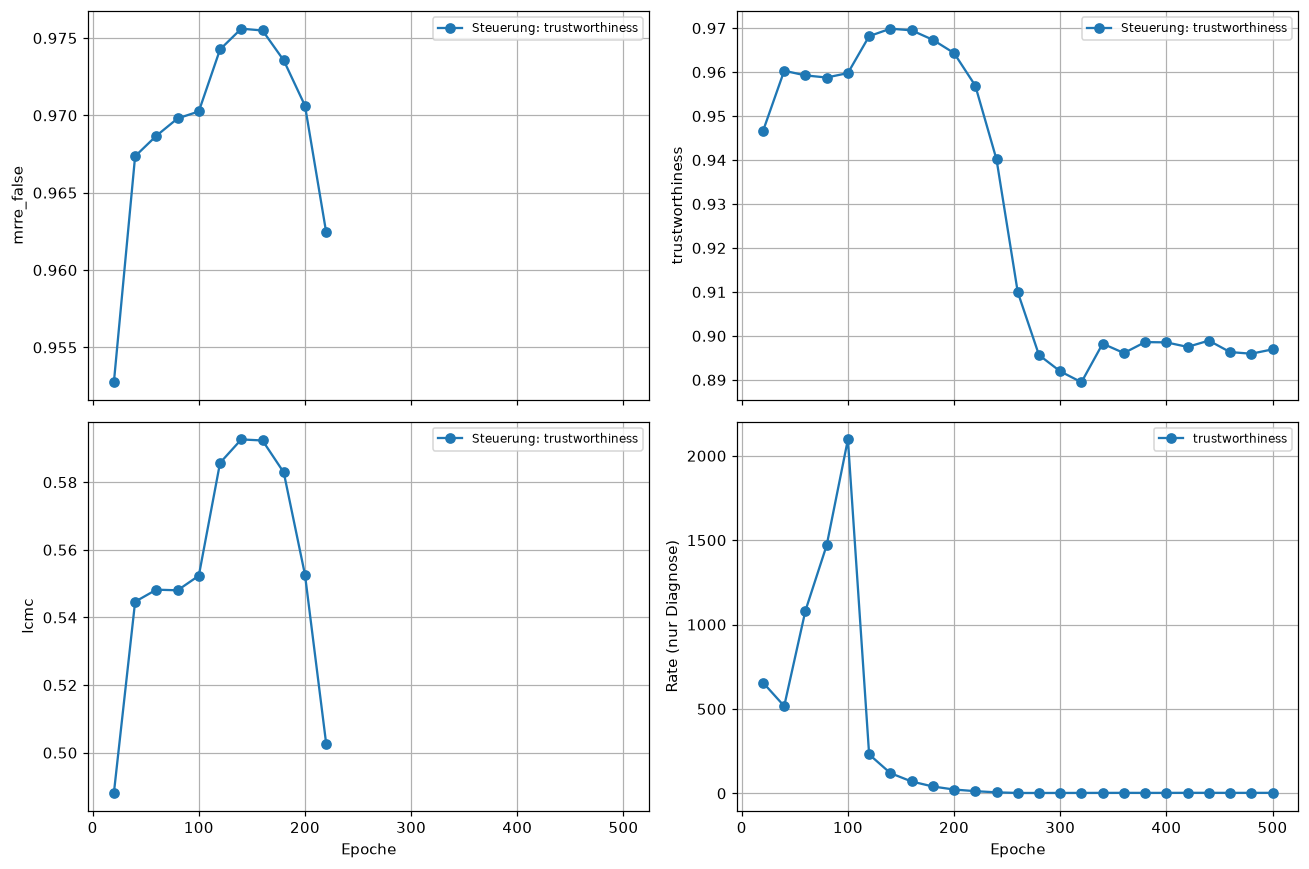

,variant,epoch,rate,collapsed_dimensions,status
0,trustworthiness,20,656.699988,0,ok
1,trustworthiness,40,516.985608,0,ok
2,trustworthiness,60,1082.330722,0,ok
3,trustworthiness,80,1469.638675,0,ok
4,trustworthiness,100,2096.886719,0,ok
5,trustworthiness,120,230.718567,0,ok
6,trustworthiness,140,120.029845,0,ok
7,trustworthiness,160,70.396507,0,ok
8,trustworthiness,180,40.764958,0,ok
9,trustworthiness,200,22.720143,0,ok


In [6]:
posterior_rows, comparison_rows = [], []
collapse = PosteriorCollapseConfig()
for variant, folder in runs.items():
    policy = PreservationAnnealingConfig(**json.loads((folder / "controller_config.json").read_text())["settings"])
    with np.load(folder / "controller_validation_reference.npz") as reference:
        x_reference = reference["x"]
        reference_ids = reference["sample_ids"].astype(str)
    for path in sorted((folder / "epoch_snapshots").glob("epoch_*_valid.npz")):
        epoch = int(path.stem.split("_")[1])
        with np.load(path) as saved:
            if not {"mu", "logvar", "sample_ids"} <= set(saved.files):
                posterior_rows.append(dict(variant=variant, epoch=epoch, status="missing_posterior"))
                continue
            positions = pd.Index(saved["sample_ids"].astype(str)).get_indexer(reference_ids)
            if (positions < 0).any():
                raise ValueError("Validation-Kohorte hat sich geändert")
            mu, logvar = saved["mu"][positions], saved["logvar"][positions]
        kl = compute_conditional_kl_matrix(mu, logvar)
        posterior_rows.append(dict(variant=variant, epoch=epoch, rate=kl.sum(1).mean(),
            collapsed_dimensions=int(np.sum(np.mean(kl < collapse.primary_epsilon, axis=0) >= 1-collapse.delta)), status="ok"))
        for metric in CANDIDATES:
            value, status, warning = np.nan, "ok", None
            try:
                value = measure_preservation(x_reference, mu, replace(policy, metric=metric))
            except (ValueError, RuntimeError, KeyError, ZeroDivisionError) as error:
                status, warning = "unavailable", str(error)
            comparison_rows.append(dict(variant=variant, epoch=epoch, metric=metric, value=value, status=status, warning=warning))
posterior = pd.DataFrame(posterior_rows, columns=["variant", "epoch", "rate", "collapsed_dimensions", "status"])
comparisons = pd.DataFrame(comparison_rows, columns=["variant", "epoch", "metric", "value", "status", "warning"])
posterior.to_csv(OUTPUT_ROOT / f"{PRESET}_rate_collapse.csv", index=False)
comparisons.to_csv(OUTPUT_ROOT / f"{PRESET}_selected_metrics.csv", index=False)
if runs:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    for ax, metric in zip(axes.flat, CANDIDATES):
        for variant, group in comparisons[comparisons.metric.eq(metric)].groupby("variant"):
            ax.plot(group.epoch, group.value, "o-", label=f"Steuerung: {variant}")
        ax.set_ylabel(metric); ax.legend(fontsize=8)
    for variant, group in posterior.groupby("variant"):
        axes[1, 1].plot(group.epoch, group.rate, "o-", label=variant)
    axes[1, 1].set_ylabel("Rate (nur Diagnose)")
    for ax in axes[-1]: ax.set_xlabel("Epoche")
    axes[1, 1].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUTPUT_ROOT / f"{PRESET}_metrics_and_rate.png", dpi=160)
    plt.show()
    display(posterior)
else:
    print("Noch keine trainierten Modelle für die Snapshot-Auswertung.")

## 6. Cancer-AUC: acht und alle 33 Krebsarten

Die Auswertung nutzt gespeichertes z und den nativen AUTOENCODIX-Presplit-Evaluator:
Logistische Regression auf Train, AUC auf Validation, alle Klassen ohne Top-20-Limit.
Acht Präsentationsklassen: BRCA, COAD, LUAD, LUSC, OV, READ, UCEC, UCS.
Das Training nutzt weiterhin die vollständige Kohorte; die Acht-Klassen-Auswertung
ist ein zweiter nachträglicher Probe auf denselben Modell-Snapshots.

Die Prozenttabelle zeigt für den ersten beobachteten relativen AUC-Abfall von 5 %,
wie viel des jeweiligen Metrik-Ausgangswerts im letzten Snapshot davor vorhanden war.
Referenz ist der erste gespeicherte Snapshot nach dem Warm-up. Ohne beobachteten
Abfall wird kein Kipppunkt erfunden. Das ist eine nachträgliche Analyse, keine
Schwellenoptimierung und kein Beweis zeitlicher Frühwarnung.

/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/nickok/Projects/MasterThesis/vae-beta-control/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
   

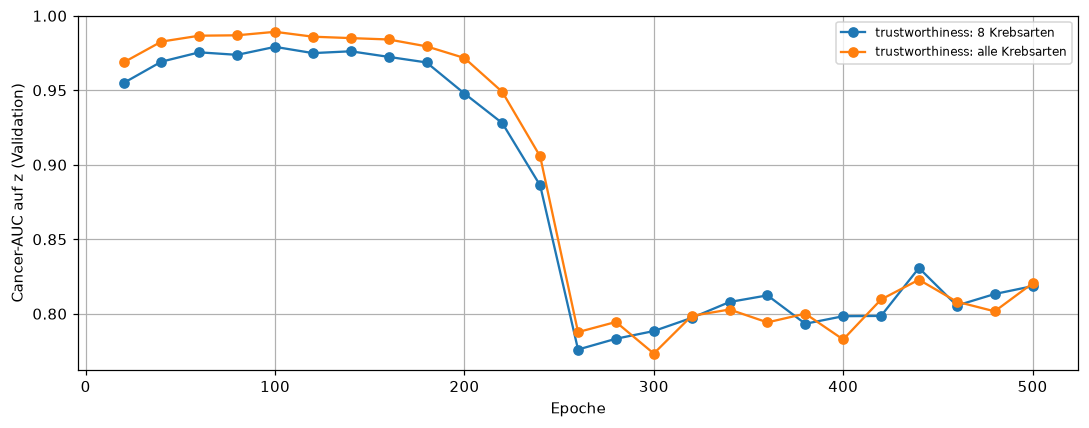

,variant,cohort,metric,baseline_epoch,last_before_drop,first_drop,metric_retained_percent,status
0,trustworthiness,8 Krebsarten,mrre_false,100,200,220,100.038521,Beobachteter Abfall
1,trustworthiness,8 Krebsarten,trustworthiness,100,200,220,100.473758,Beobachteter Abfall
2,trustworthiness,8 Krebsarten,lcmc,100,200,220,100.056577,Beobachteter Abfall
3,trustworthiness,alle Krebsarten,mrre_false,100,220,240,99.193725,Beobachteter Abfall
4,trustworthiness,alle Krebsarten,trustworthiness,100,220,240,99.702178,Beobachteter Abfall
5,trustworthiness,alle Krebsarten,lcmc,100,220,240,90.992927,Beobachteter Abfall


Ergebnisse: /home/nickok/Projects/MasterThesis/vae-beta-control/beta_vae_experiments/outputs/cancer_annealing_focus


In [7]:
from sklearn.linear_model import LogisticRegression
from beta_vae_experiments.metrics.evaluation.downstream import ClassAUCEvaluator

CANCERS_8 = ("BRCA", "COAD", "LUAD", "LUSC", "OV", "READ", "UCEC", "UCS")
auc_rows = []
for variant, folder in runs.items():
    label_path = folder / "epoch_snapshots" / "labels_train.parquet"
    if not label_path.exists() or "CANCER_TYPE_ACRONYM" not in pd.read_parquet(label_path):
        print(variant, ": CPU-Demo hat keine Krebslabels; keine Cancer-AUC erfunden.")
        continue
    for path in sorted((folder / "epoch_snapshots").glob("epoch_*_valid.npz")):
        epoch = int(path.stem.split("_")[1])
        for cohort in ("8 Krebsarten", "alle Krebsarten"):
            features, annotations, partitions = [], [], []
            for split in ("train", "valid"):
                with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_{split}.npz") as saved:
                    ids, z = saved["sample_ids"].astype(str), saved["z"]
                labels = pd.read_parquet(folder / "epoch_snapshots" / f"labels_{split}.parquet")
                labels.index = labels.index.astype(str); labels = labels.loc[ids]
                keep = labels.CANCER_TYPE_ACRONYM.isin(CANCERS_8) if cohort == "8 Krebsarten" else np.ones(len(labels), dtype=bool)
                selected_ids = ids[np.asarray(keep)]
                features.append(pd.DataFrame(z[np.asarray(keep)], index=selected_ids))
                annotations.append(labels.loc[selected_ids, ["CANCER_TYPE_ACRONYM"]])
                partitions.append(pd.DataFrame(dict(SAMPLE_ID=selected_ids, SPLIT=split)))
            value, status, warning = np.nan, "ok", None
            try:
                scores = ClassAUCEvaluator()._single_ml_presplit(
                    pd.concat(partitions, ignore_index=True), pd.concat(features), pd.concat(annotations),
                    "CANCER_TYPE_ACRONYM", LogisticRegression(max_iter=1000), "roc_auc_ovo", "classification", top_k_classes=None)
                value = float(scores.loc[scores.score_split.eq("valid"), "value"].iloc[0])
                if not np.isfinite(value): status = "unavailable"
            except (ValueError, IndexError) as error:
                status, warning = "unavailable", str(error)
            auc_rows.append(dict(variant=variant, epoch=epoch, cohort=cohort, auc=value, status=status, warning=warning))
auc = pd.DataFrame(auc_rows, columns=["variant", "epoch", "cohort", "auc", "status", "warning"])
auc.to_csv(OUTPUT_ROOT / f"{PRESET}_cancer_auc.csv", index=False)
if not auc.empty:
    fig, ax = plt.subplots(figsize=(10, 4))
    for (variant, cohort), group in auc.groupby(["variant", "cohort"]):
        ax.plot(group.epoch, group.auc, "o-", label=f"{variant}: {cohort}")
    ax.set(xlabel="Epoche", ylabel="Cancer-AUC auf z (Validation)"); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUTPUT_ROOT / f"{PRESET}_cancer_auc.png", dpi=160); plt.show()
    retained = []
    for (variant, cohort), group in auc[auc.status.eq("ok")].groupby(["variant", "cohort"]):
        group = group[group.epoch >= parameters["warmup_epochs"]].sort_values("epoch")
        if group.empty: continue
        first = group.iloc[0]
        drops = group[group.auc < 0.95 * first.auc]
        if drops.empty:
            retained.append(dict(variant=variant, cohort=cohort, status="Kein 5%-Abfall beobachtet")); continue
        crossing = drops.iloc[0]
        before = group[group.epoch < crossing.epoch].iloc[-1]
        for metric in CANDIDATES:
            trajectory = comparisons[(comparisons.variant == variant) & comparisons.metric.eq(metric)].set_index("epoch")
            baseline = trajectory.loc[first.epoch, "value"]
            value = trajectory.loc[before.epoch, "value"]
            retained.append(dict(variant=variant, cohort=cohort, metric=metric, baseline_epoch=first.epoch,
                last_before_drop=before.epoch, first_drop=crossing.epoch,
                metric_retained_percent=100*value/baseline if baseline > 0 else np.nan, status="Beobachteter Abfall"))
    retention = pd.DataFrame(retained)
    retention.to_csv(OUTPUT_ROOT / f"{PRESET}_preservation_before_auc_drop.csv", index=False)
    display(retention)
else:
    print("Cancer-AUC wird erst nach einem TCGA-Lauf ausgewertet.")
print("Ergebnisse:", OUTPUT_ROOT)

## Was dieser Versuch beantwortet

- Kann die gewählte hoch korrelierte Preservation-Metrik das native β-Annealing steuern?
- Wie verhalten sich Rate und ε-δ-Collapse dabei, ohne als Regelsignal zu dienen?
- Bleibt Cancer-AUC auf z erhalten, für acht und alle Krebsarten?
- Wie viel Preservation war unmittelbar vor einem beobachteten AUC-Abfall noch vorhanden?

Hohe Korrelation allein garantiert weder Downstream-Erhalt noch Collapse-Vermeidung.
Erst diesen fokussierten Versuch prüfen, danach Large Scale mit dem geprüften Stand
fortsetzen. Der Quellstand hat sich geändert; die frühere Serienfreigabe wird nicht
ungeprüft wiederverwendet. Es wird keine Metrikformel im Notebook nachgebaut.

## 7. Überblick: Ziel 0,7 gegen Ziel 0,9

Beide Läufe: TCGA, d = 8, Seed 17, 100 Epochen Warm-up, Messung alle 5 Epochen.
Ziel 0,7: 1.000 Epochen, Wachstumsfaktor 1,10. Ziel 0,9: 500 Epochen, Wachstumsfaktor 1,25.
β/d und Trustworthiness stammen aus dem Controller-Log (Validierungs-Subset, alle 5 Epochen),
Rate und Cancer-AUC aus den Snapshots (alle 20 Epochen, AUC auf z, Validation).
Die Sammeldateien des 0,7-Laufs liegen in `summary_target_0.70/`, weil `tcga_pilot_*` vom
jeweils letzten Lauf überschrieben wird.

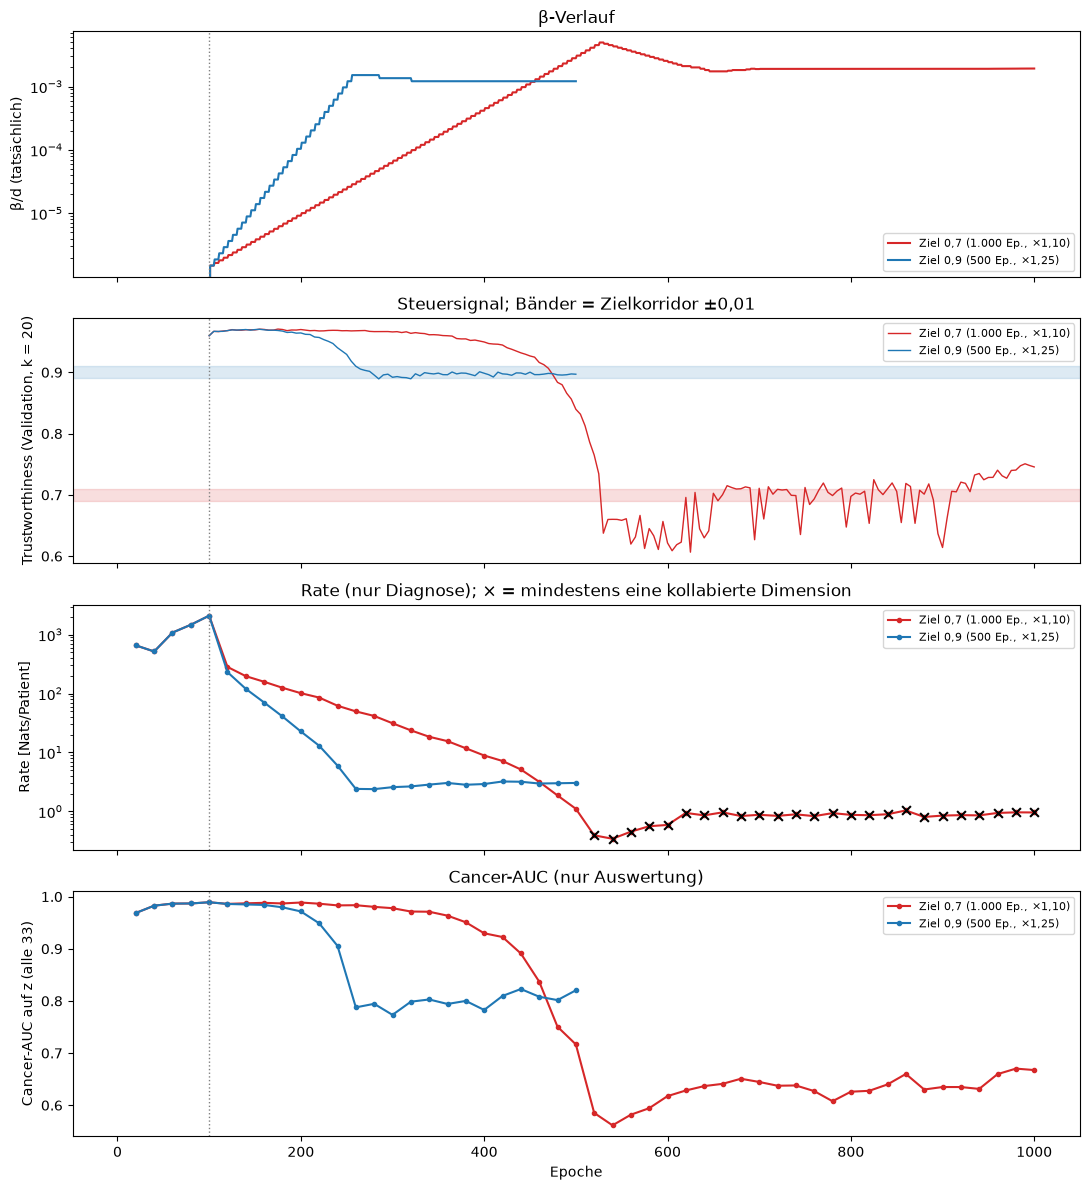

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

FOCUS = Path.cwd() / "outputs" / "cancer_annealing_focus" if Path.cwd().name == "beta_vae_experiments" \
    else Path.cwd() / "beta_vae_experiments" / "outputs" / "cancer_annealing_focus"
COMPARED = {
    "Ziel 0,7 (1.000 Ep., ×1,10)": ("tcga_pilot_trustworthiness_bab147caaa", FOCUS / "summary_target_0.70"),
    "Ziel 0,9 (500 Ep., ×1,25)": ("tcga_pilot_trustworthiness_a7bee9448a", FOCUS),
}
fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
for (label, (run, summary)), color in zip(COMPARED.items(), ("tab:red", "tab:blue")):
    controller = pd.read_csv(next((FOCUS / run / "run_analysis").glob("*/controller_log.csv")))
    measured = controller.dropna(subset=["metric_value"])
    rate = pd.read_csv(summary / "tcga_pilot_rate_collapse.csv")
    auc = pd.read_csv(summary / "tcga_pilot_cancer_auc.csv")
    auc = auc[auc.cohort.eq("alle Krebsarten")]
    target = controller.target.iloc[-1]
    axes[0].plot(controller.epoch, controller.beta_over_d, color=color, label=label)
    axes[1].plot(measured.epoch, measured.metric_value, color=color, lw=1, label=label)
    axes[1].axhspan(target - controller.tolerance.iloc[-1], target + controller.tolerance.iloc[-1], color=color, alpha=.15)
    axes[2].plot(rate.epoch, rate.rate, "o-", ms=3, color=color, label=label)
    collapsed = rate[rate.collapsed_dimensions > 0]
    axes[2].scatter(collapsed.epoch, collapsed.rate, marker="x", s=40, color="black", zorder=3)
    axes[3].plot(auc.epoch, auc.auc, "o-", ms=3, color=color, label=label)
axes[0].set(yscale="log", ylabel="β/d (tatsächlich)", title="β-Verlauf")
axes[1].set(ylabel="Trustworthiness (Validation, k = 20)", title="Steuersignal; Bänder = Zielkorridor ±0,01")
axes[2].set(yscale="log", ylabel="Rate [Nats/Patient]", title="Rate (nur Diagnose); × = mindestens eine kollabierte Dimension")
axes[3].set(ylabel="Cancer-AUC auf z (alle 33)", xlabel="Epoche", title="Cancer-AUC (nur Auswertung)")
for ax in axes:
    ax.axvline(100, color="gray", ls=":", lw=1)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FOCUS / "tcga_pilot_target_0.7_vs_0.9.png", dpi=160)
plt.show()